# **2. Khám phá dữ liệu (EDA)**

Tập trung vào **số khách** (`Customers`), đại lượng mới so với đồ án 1, và mối quan hệ giữa số khách với doanh thu. Notebook này **không thay đổi dữ liệu**.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

import features as F

FIG_DIR = Path('figures')
FIG_DIR.mkdir(exist_ok=True)
PROCESSED_DIR = Path('data/processed')

def save_fig(name):
    """Lưu hình đang vẽ vào figures/<name>.png."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150)

full = pd.read_parquet(PROCESSED_DIR / 'rossmann_full.parquet')
my_data = full[F.is_trainable(full)].copy()           # chỉ ngày mở cửa và có doanh thu
my_data['Basket'] = my_data['Sales'] / my_data['Customers']   # giá trị trung bình mỗi lượt mua
print(my_data.shape)

(844338, 20)


**2.1 Phân phối của số khách**

count    844338.0
mean        762.8
std         401.2
min           8.0
25%         519.0
50%         676.0
75%         893.0
max        7388.0
Name: Customers, dtype: float64
Độ lệch (skewness): 2.79


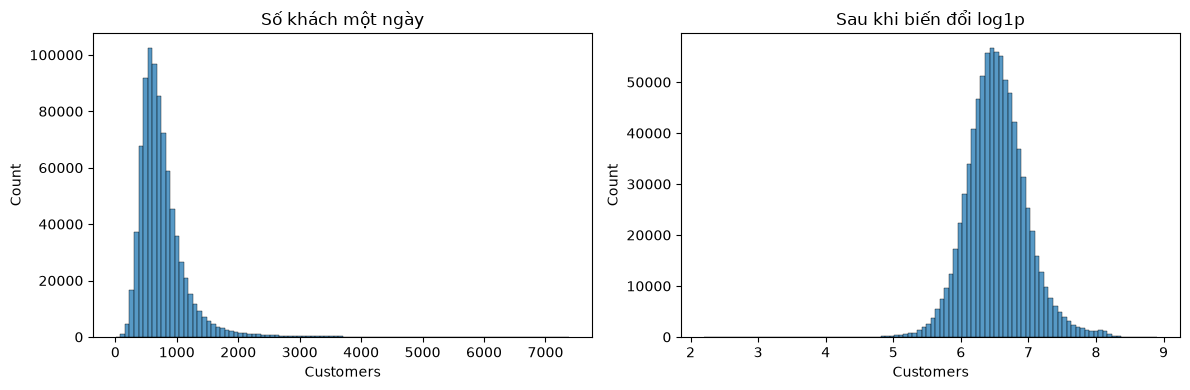

In [2]:
print(my_data['Customers'].describe().round(1))
print('Độ lệch (skewness):', round(my_data['Customers'].skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(my_data['Customers'], bins=100, ax=axes[0])
axes[0].set_title('Số khách một ngày')
sns.histplot(np.log1p(my_data['Customers']), bins=100, ax=axes[1])
axes[1].set_title('Sau khi biến đổi log1p')
save_fig('customers_hist')

**Nhận xét:** trung bình 763 khách/ngày, trung vị 676, độ lệch 2,79, tức lệch phải mạnh hơn cả doanh thu (1,59 ở đồ án 1). Nguyên nhân là một số ít cửa hàng có lượng khách rất lớn (tối đa 7.388 khách/ngày). Sau `log1p` phân phối cân đối hơn, nên mô hình sẽ học trên log(số khách), giống cách làm với doanh thu.

**2.2 Quan hệ giữa số khách và doanh thu**

Tương quan Customers – Sales: 0.824
count    844338.00
mean          9.49
std           2.20
min           2.75
25%           7.90
50%           9.25
75%          10.90
max          64.96
Name: Basket, dtype: float64


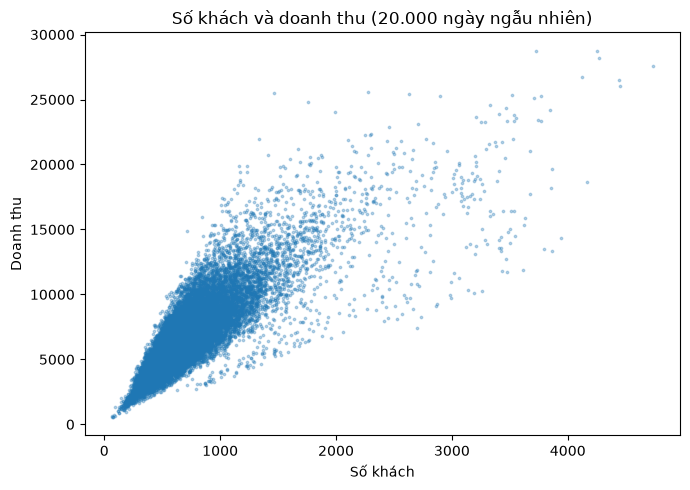

In [3]:
print('Tương quan Customers – Sales:', round(my_data['Customers'].corr(my_data['Sales']), 3))
print(my_data['Basket'].describe().round(2))

sample = my_data.sample(20_000, random_state=0)
plt.figure(figsize=(7, 5))
plt.scatter(sample['Customers'], sample['Sales'], s=3, alpha=0.3)
plt.xlabel('Số khách'); plt.ylabel('Doanh thu')
plt.title('Số khách và doanh thu (20.000 ngày ngẫu nhiên)')
save_fig('customers_vs_sales')

**Nhận xét:** số khách và doanh thu tương quan 0,82, nhưng các điểm toả rộng thành hình quạt: cùng một số khách, doanh thu có thể chênh nhau gấp đôi. Giá trị mỗi lượt mua trung bình 9,49, phần lớn nằm trong khoảng 7,9–10,9. Vì vậy cần dự báo **riêng** hai đại lượng: số khách để xếp nhân viên, doanh thu để chuẩn bị hàng.

**2.3 Số khách theo thứ trong tuần**

           Customers   Sales  Basket  Số quan sát
DayOfWeek                                        
1              855.5  8216.3     9.9       137557
2              770.0  7088.4     9.6       143955
3              740.7  6728.8     9.5       141922
4              755.7  6768.2     9.4       134626
5              781.8  7073.0     9.4       138633
6              660.2  5875.1     9.3       144052
7             1441.5  8224.7     6.5         3593


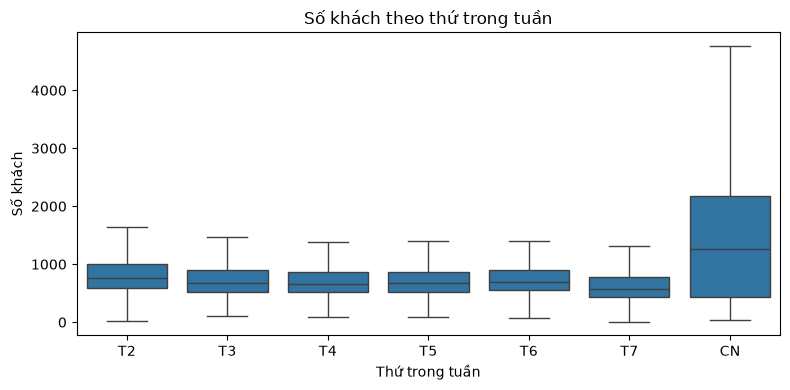

In [4]:
by_dow = my_data.groupby('DayOfWeek')[['Customers', 'Sales', 'Basket']].mean().round(1)
by_dow['Số quan sát'] = my_data.groupby('DayOfWeek').size()
print(by_dow)

plt.figure(figsize=(8, 4))
sns.boxplot(data=my_data, x='DayOfWeek', y='Customers', showfliers=False)
plt.xticks(range(7), ['T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'CN'])
plt.xlabel('Thứ trong tuần'); plt.ylabel('Số khách')
plt.title('Số khách theo thứ trong tuần')
save_fig('customers_dow_box')

**Nhận xét:** thứ Hai đông khách nhất (856), thứ Bảy vắng nhất (660). Chủ nhật có 1.442 khách nhưng chỉ có 3.593 quan sát vì rất ít cửa hàng mở cửa, và khách Chủ nhật mua ít hơn hẳn (6,5 mỗi lượt so với khoảng 9,5 ngày thường). Số khách dao động theo thứ ít hơn doanh thu: thứ Hai cao hơn thứ Bảy khoảng 30% về số khách nhưng khoảng 40% về doanh thu.

**2.4 Khuyến mãi làm tăng số khách hay tăng giá trị mỗi lượt mua?**

Doanh thu = số khách × giá trị mỗi lượt mua (`Basket`). Tách doanh thu ra hai phần này để biết khuyến mãi tác động vào đâu.

       Customers  Basket   Sales
Promo                           
0          696.9     8.9  5929.8
1          844.5    10.2  8228.7
Mức tăng khi có khuyến mãi (%): {'Customers': 21.2, 'Basket': 13.8, 'Sales': 38.8}


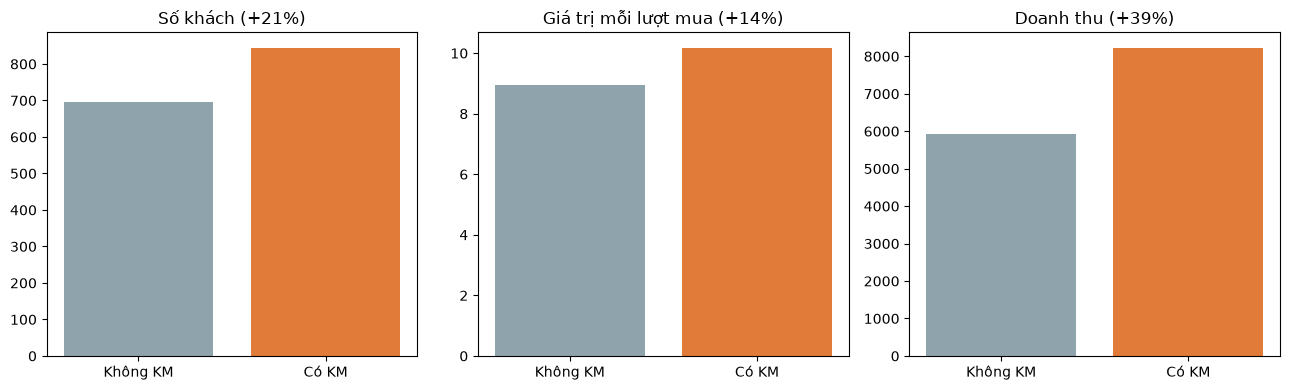

In [5]:
by_promo = my_data.groupby('Promo')[['Customers', 'Basket', 'Sales']].mean()
lift = (by_promo.loc[1] / by_promo.loc[0] - 1) * 100
print(by_promo.round(1))
print('Mức tăng khi có khuyến mãi (%):', lift.round(1).to_dict())

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col, name in zip(axes, ['Customers', 'Basket', 'Sales'], ['Số khách', 'Giá trị mỗi lượt mua', 'Doanh thu']):
    ax.bar(['Không KM', 'Có KM'], by_promo[col], color=['#8fa3ad', '#e07b39'])
    ax.set_title(f'{name} (+{lift[col]:.0f}%)')
save_fig('promo_customers_basket')

**Nhận xét:** ngày có khuyến mãi, doanh thu tăng 38,8%, trong đó số khách tăng 21,2% và giá trị mỗi lượt mua tăng 13,8% (1,212 × 1,138 ≈ 1,388). Khuyến mãi vừa kéo thêm khách vừa làm khách mua nhiều hơn, nhưng phần kéo thêm khách lớn hơn. Ý nghĩa vận hành: ngày khuyến mãi cần **thêm nhân viên**, không chỉ thêm hàng.

**2.5 Số khách theo loại cửa hàng**

          Customers         Basket       
              count  median  count median
StoreType                                
a               602   715.8    602    8.7
b                17  1758.8     17    4.9
c               148   759.5    148    8.4
d               348   586.2    348   11.4


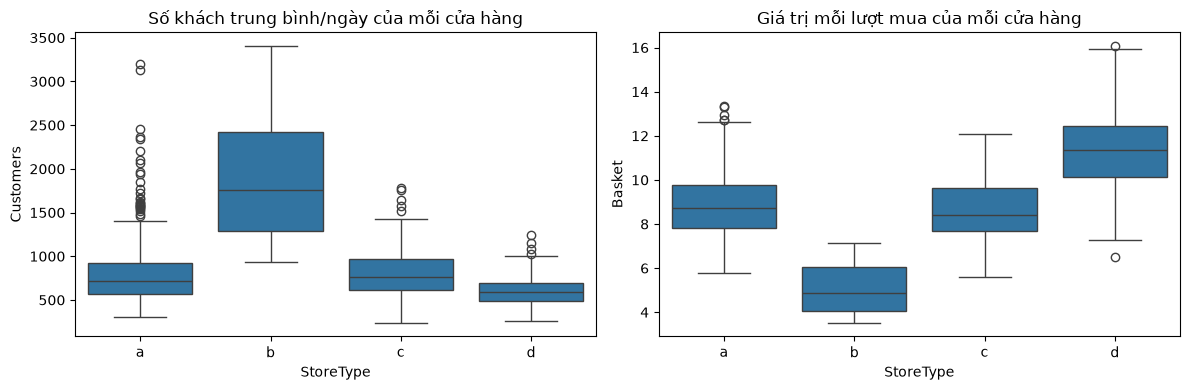

In [6]:
store_mean = my_data.groupby(['StoreType', 'Store'], as_index=False)[['Customers', 'Basket']].mean()
print(store_mean.groupby('StoreType')[['Customers', 'Basket']].agg(['count', 'median']).round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=store_mean, x='StoreType', y='Customers', order=list('abcd'), ax=axes[0])
axes[0].set_title('Số khách trung bình/ngày của mỗi cửa hàng')
sns.boxplot(data=store_mean, x='StoreType', y='Basket', order=list('abcd'), ax=axes[1])
axes[1].set_title('Giá trị mỗi lượt mua của mỗi cửa hàng')
save_fig('storetype_customers')

**Nhận xét:** loại b (17 cửa hàng) đông khách gấp khoảng 2,3 lần các loại khác (trung vị 1.759 khách/ngày) nhưng mỗi lượt chỉ mua 4,9. Loại d ít khách nhất (586) nhưng mỗi lượt mua nhiều nhất (11,4). Hai cửa hàng có cùng doanh thu có thể cần số nhân viên rất khác nhau, thêm một lý do để dự báo số khách riêng.

**2.6 Chu kỳ khuyến mãi**

Ý tưởng tự nhiên nhất khi không có mô hình là "tuần này giống tuần trước". Trước khi dùng ý tưởng đó làm baseline, cần kiểm tra khuyến mãi có lặp lại theo tuần không.

In [7]:
weekday = full[full['DayOfWeek'] <= 5].copy()            # khuyến mãi chỉ chạy từ thứ Hai đến thứ Sáu
g = full.groupby('Store')['Promo']
for k in (7, 14):
    same = (full['Promo'] == g.shift(k))[weekday.index]
    print(f'Promo hôm nay giống Promo cùng thứ cách đây {k} ngày: {same.mean() * 100:.1f}%')

print(full.loc[(full['Store'] == 1) & full['Date'].between('2015-06-01', '2015-06-28'), ['Date', 'DayOfWeek', 'Promo']]
      .set_index('Date').T)

Promo hôm nay giống Promo cùng thứ cách đây 7 ngày: 9.9%
Promo hôm nay giống Promo cùng thứ cách đây 14 ngày: 78.8%
Date       2015-06-01  2015-06-02  2015-06-03  2015-06-04  2015-06-05  \
DayOfWeek           1           2           3           4           5   
Promo               1           1           1           1           1   

Date       2015-06-06  2015-06-07  2015-06-08  2015-06-09  2015-06-10  ...  \
DayOfWeek           6           7           1           2           3  ...   
Promo               0           0           0           0           0  ...   

Date       2015-06-19  2015-06-20  2015-06-21  2015-06-22  2015-06-23  \
DayOfWeek           5           6           7           1           2   
Promo               1           0           0           0           0   

Date       2015-06-24  2015-06-25  2015-06-26  2015-06-27  2015-06-28  
DayOfWeek           3           4           5           6           7  
Promo               0           0           0           0        

**Nhận xét:** từ thứ Hai đến thứ Sáu, chỉ 9,9% số ngày có cùng trạng thái khuyến mãi với cùng thứ tuần trước, nhưng 78,8% giống cùng thứ của 2 tuần trước. Khuyến mãi chạy **xen kẽ từng tuần**: ví dụ cửa hàng 1 có khuyến mãi tuần 01/06, không có tuần 08/06, có lại tuần 15/06. Vì vậy cách đoán "giống tuần trước" thường so một ngày có khuyến mãi với một ngày không có, nên sẽ sai nhiều. Notebook 3 tạo thêm đặc trưng `same_promo`: giá trị của ngày cùng thứ, cùng trạng thái khuyến mãi gần nhất.

**2.7 Tự tương quan của số khách**

Giống đồ án 1, xét chuỗi số khách trung bình mỗi cửa hàng theo ngày. ACF cho biết số khách hôm nay giống số khách cách đây k ngày tới mức nào; PACF cho biết phần liên quan **riêng** của từng độ trễ.

Tự tương quan ở lag 1, 7, 14:
        Customers  Sales
lag_1      -0.047  0.429
lag_7       0.725  0.152
lag_14      0.732  0.581


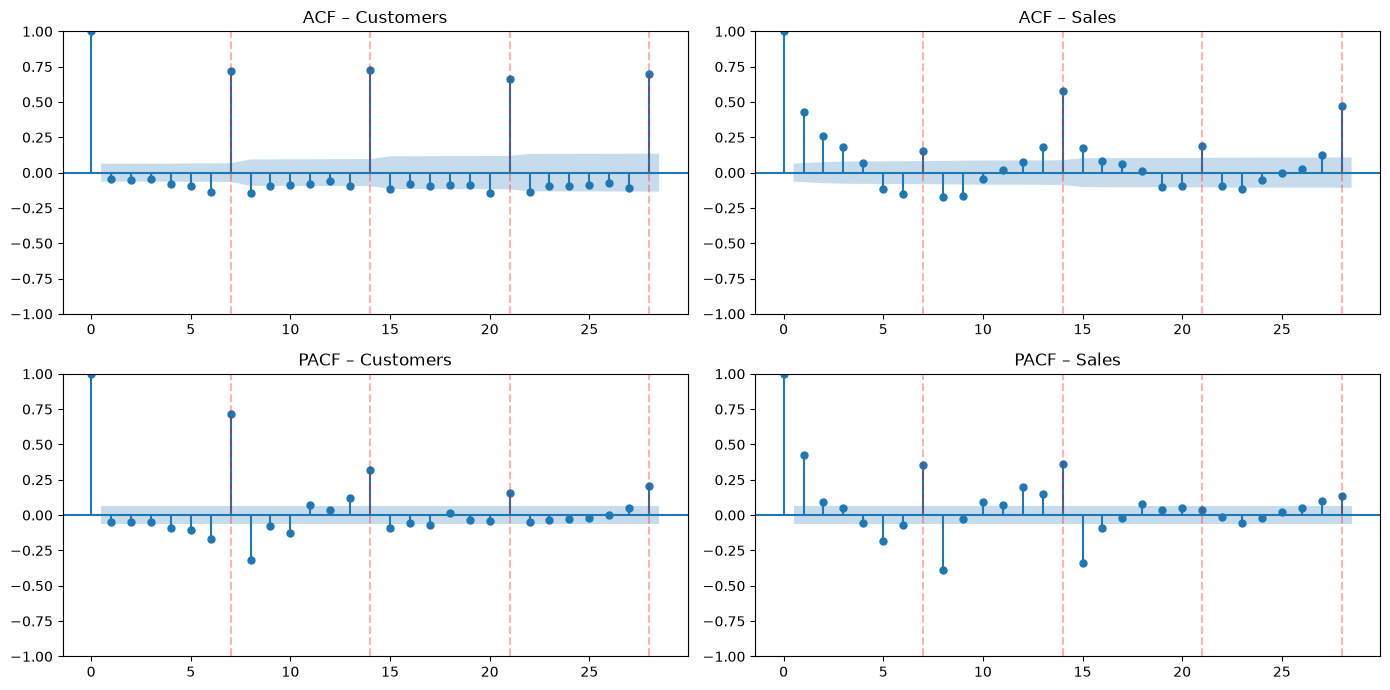

In [8]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

daily = my_data.groupby('Date')[['Customers', 'Sales']].mean()
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
for j, col in enumerate(['Customers', 'Sales']):
    plot_acf(daily[col], lags=28, ax=axes[0, j], title=f'ACF – {col}')
    plot_pacf(daily[col], lags=28, ax=axes[1, j], method='ywm', title=f'PACF – {col}')
    for ax in axes[:, j]:
        for k in (7, 14, 21, 28):
            ax.axvline(k, color='red', ls='--', alpha=0.3)
save_fig('acf_pacf_customers_sales')
print('Tự tương quan ở lag 1, 7, 14:')
print(pd.DataFrame({col: [daily[col].autocorr(k) for k in (1, 7, 14)] for col in ['Customers', 'Sales']},
                   index=['lag_1', 'lag_7', 'lag_14']).round(3))

**Nhận xét:** với doanh thu, tự tương quan ở lag 14 (0,58) cao hơn hẳn lag 7 (0,15), khớp với chu kỳ khuyến mãi 2 tuần ở mục 2.6. Với số khách, lag 7 (0,73) và lag 14 (0,73) gần như bằng nhau, vì khuyến mãi tác động lên số khách ít hơn lên doanh thu (+21% so với +39%). Tự tương quan lag 1 của số khách gần 0 (−0,05) là do chuỗi trung bình cả chuỗi bị Chủ nhật làm méo: Chủ nhật ít cửa hàng mở nhưng mỗi cửa hàng rất đông khách. Ở mức từng cửa hàng, độ trễ 1 ngày vẫn hữu ích (đồ án 1 đã cho thấy, notebook 3 kiểm tra lại). Vì vậy chọn lag 1, 2 cho h = 1; lag 7, 14, 21, 28 và trung bình cùng thứ cho cả hai horizon.

**Kết luận:**
- Số khách lệch phải mạnh, nên học trên `log1p`.
- Số khách và doanh thu liên quan chặt (0,82) nhưng không thay thế được nhau: giá trị mỗi lượt mua khác nhiều giữa các loại cửa hàng và giữa ngày thường với Chủ nhật.
- Khuyến mãi tăng số khách 21% và tăng giá trị mỗi lượt mua 14%, nên ngày khuyến mãi cần thêm cả nhân viên lẫn hàng.
- Chu kỳ tuần rất mạnh, và khuyến mãi xen kẽ theo chu kỳ 2 tuần. Baseline và đặc trưng độ trễ phải tính đến trạng thái khuyến mãi.